# Exercise 4.1 | Numerical Predictors

Are wealthier countries happier? The World Happiness Report asks people in each country to rate their lives on a 0–10 scale. We'll pair those ratings with GDP per capita from the World Bank and fit a bivariate GLM with a numerical predictor:

$$y_i = \beta_0 + \beta_1 x_i + \epsilon_i$$

The outcome ($y$) is **Life Evaluation** (0–10 scale) and the predictor ($x$) is **log10 GDP per capita**. We use the 2024 observations, one per country. Complete the notebook, then enter your answers in Gradescope.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

The dataset `Life_Evaluation_GDP_PerCap.csv` has one row per country and year, with life evaluation from the Gallup World Poll and GDP per capita from the World Bank. We take the log10 of GDP per capita and keep only 2024. One country is missing GDP per capita in 2024; `statsmodels` drops it automatically when fitting.

In [2]:
# Load Data
data = pd.read_csv(file_path + 'Life_Evaluation_GDP_PerCap.csv')
# Log10 of GDP per capita
data['log_GDP_PerCap'] = np.log10(data['GDP_Per_Cap'])
# Keep 2024
data = data[data['Year'] == 2024]
# Display header
data.head()

,Year,Country,Life_Evaluation,GDP_Per_Cap,log_GDP_PerCap
0,2024,Afghanistan,1.364,549.27,2.739786
13,2024,Albania,5.411,5411.94,3.733353
26,2024,Algeria,5.571,4361.21,3.639607
45,2024,Argentina,6.397,11107.35,4.045610
58,2024,Armenia,5.494,5016.99,3.700443


## Explore the Data

**Question 1.** Make a scatter plot with `log_GDP_PerCap` on the x-axis and `Life_Evaluation` on the y-axis. Is there a visible relationship? Which direction does it go?

*Hint: `sns.scatterplot(data=data, x='log_GDP_PerCap', y='Life_Evaluation')`*

<Axes: xlabel='log_GDP_PerCap', ylabel='Life_Evaluation'>

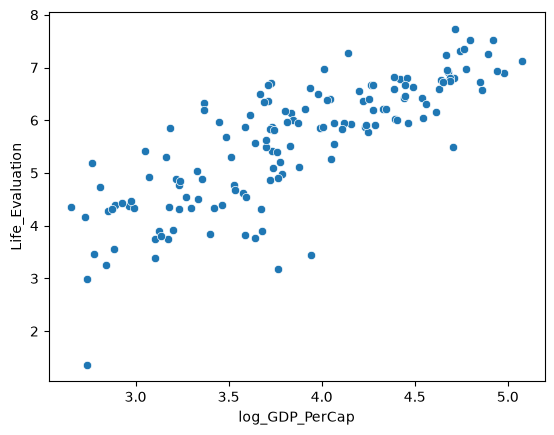

In [3]:
sns.scatterplot(data=data, x='log_GDP_PerCap', y='Life_Evaluation')

{++Yes. The relationship is positive: countries with higher log GDP per capita have higher life evaluation.++}

## Fitting the Model

We fit the bivariate GLM:

$$LifeEvaluation_i = \beta_0 + \beta_1 \cdot logGDP_i + \epsilon_i$$

Just like the intercept-only model, the GLM chooses the $\beta_0$ and $\beta_1$ that minimize MSE: the line that is least wrong. In `statsmodels` the model is written `Life_Evaluation ~ log_GDP_PerCap`.

**Question 2.** Fit the model and print the coefficient table.

*Hint: save `smf.ols('Life_Evaluation ~ log_GDP_PerCap', data=data).fit()` as `model`, then use `print(model.summary().tables[1])`.*

In [4]:
# Model: y = b + mx
model = smf.ols('Life_Evaluation ~ log_GDP_PerCap', data=data).fit() # Intercept is included by default
print(model.summary().tables[1])

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.2502      0.364     -0.687      0.493      -0.970       0.469
log_GDP_PerCap     1.5145      0.093     16.225      0.000       1.330       1.699


**Question 3.** Visualize the fitted model by making a scatter plot with the regression line overlaid.

*Hint: `sns.regplot(data=data, x='log_GDP_PerCap', y='Life_Evaluation', ci=None)`*

<Axes: xlabel='log_GDP_PerCap', ylabel='Life_Evaluation'>

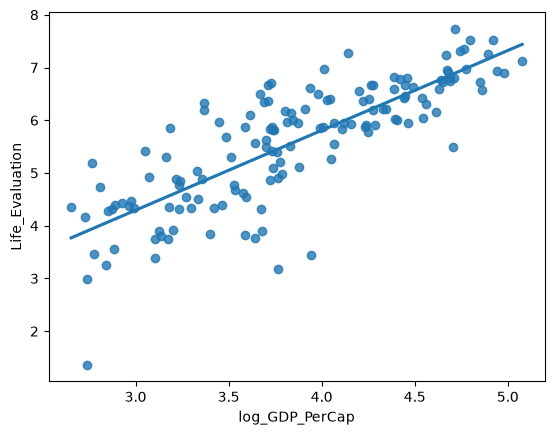

In [5]:
# Visualize: Numerical x Numerical
sns.regplot(data=data, x='log_GDP_PerCap', y='Life_Evaluation', ci=None)

**Question 4.** What is the estimated slope ($\hat{\beta}_1$)? Is it positive or negative?

What is the p-value on the slope, and what null hypothesis does it test?

{++The estimated slope is 1.515. It is positive.++}

{++The p-value on the slope is 0.000.++} $H_0: \beta_1 = 0$. There is no linear relationship between {++log GDP per capita and life evaluation++}.

## Predictions

Once we have the estimates $\hat{\beta}_0$ and $\hat{\beta}_1$, we can predict life evaluation for any value of log GDP per capita:

$$\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 \cdot x$$

**Question 5.** Extract the estimated parameters from your model, then predict life evaluation for a country with log10 GDP per capita of 3 (GDP per capita of \$1,000).

*Hint: the estimates are `model.params['Intercept']` and `model.params['log_GDP_PerCap']`.*

In [6]:
# Parameters
b0, b1 = model.params  # intercept, slope

# Predict: Log GDP of 3
prediction = b0 + b1 * 3
print(prediction)

4.293437421850511


**Question 6.** Predict life evaluation for a country with log10 GDP per capita of 4 (GDP per capita of \$10,000). How much higher is this prediction than the one in Question 5? Does the difference make sense given the slope?

In [7]:
# Predict: Log GDP of 4
prediction_4 = b0 + b1 * 4
print(prediction_4)

# Difference
print(prediction_4 - prediction)

5.807970911938653
1.5145334900881418


{++The prediction is 5.808, which is 1.515 higher than the prediction in Question 5. The difference is the slope:++} $\beta_1$ is the change in $\hat{y}$ per unit change in $x$.

## Interpretation

**Question 7.** Write a one-sentence interpretation of the slope $\hat{\beta}_1$ in context. Use the format: "For every one-unit increase in [x], [y] increases/decreases by [amount].\"

For every one-unit increase in log GDP per capita, life evaluation increases by {++1.515++} points.

**Question 8.** What does a one-unit increase in *log10* GDP per capita mean in terms of *actual* GDP per capita?

{++GDP per capita is 10 times larger.++}